In [7]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.sparse import linalg as sla
from myfunctions import rk4solve, lagint, minimum_finder
from part2 import H_number, H_time
from part3 import Lindblad

In [ ]:
#optimisation idea instead of turning the drive directly on and off I will try to optimize it
# By making it a gaussian function with the amplitude omega and optimize omega0 so it is as close to 1 as possible at the end of the gate time.
def gaussian(t,mu,sigma):
    return( np.exp( -(t-mu)**2 /(2 * sigma**2 )))

In [41]:
#create the hamilton and the initial density matrix
##
E_c = 2*np.pi * 0.25   # rad/ns is E_c/h 0.25 GHz
E_j = 2*np.pi * 12.5   # rad/ns # same as before is E_j/h 12.5 GHz
N=np.arange(-10,11,1) # the number of Cooper pairs from -10 to 10
t1, t2= 200, 150 # the relaxation and dephasing times in ns
gamma= np.array([1/t1,2 * (1/t2 - 1 / (2*t1))]) # the dissipation rates for the two levels
T1 = np.array([[0,1,0],[0,0,np.sqrt(2)],[0,0,0]],dtype=complex) # the lowering operator a on 3 levels
T2 = np.diag([0,1,2]) # adagger a 
T = np.array([T1,T2]) # the array of the two operators
T_g = 10 # gate time
dT_g=0.005 # stepsize
rho0 = np.array([[1,0,0],[0,0,0],[0,0,0]],dtype=complex) # the initial density matrix

#
mu = T_g/2 # the amplitude is at its maximum at half of the gate time
sigma = T_g/6 # make sure it is close to zero in the start and end
#omega0= E_c/4  # the amplitude of the drive must be smaller than E_c
omega0 = 0.6948224704631465
#
H_num = H_number(N, E_c, E_j) # the hamiltonian in n basis
E,U= sla.eigsh(H_num, k=3, which='SA') # the eigenvalues and eigenvectors in n basis
H_0= np.diag(E,0)- E[0] * np.eye(3) # the diagonal matrix of the eigenvalues with the ground state energy subtracted so that the ground state energy is zero.
w = E[1]-E[0] # the energy gap between the ground state and the first excited state
A= U.T @ np.diag(N) @ U #the coupling term between the different states
### Solve the Lindblad equation using RK4
def f(t,rho): # the function that will be used in the RK4 method to solve the Lindblad equation
    omega = omega0*gaussian(t,mu,sigma) 
    H = H_time(t,H_0,A,omega,w)
    return Lindblad(T, rho, H, gamma)
t_L,C_L = rk4solve(f, rho0, 0, dT_g, T_g)

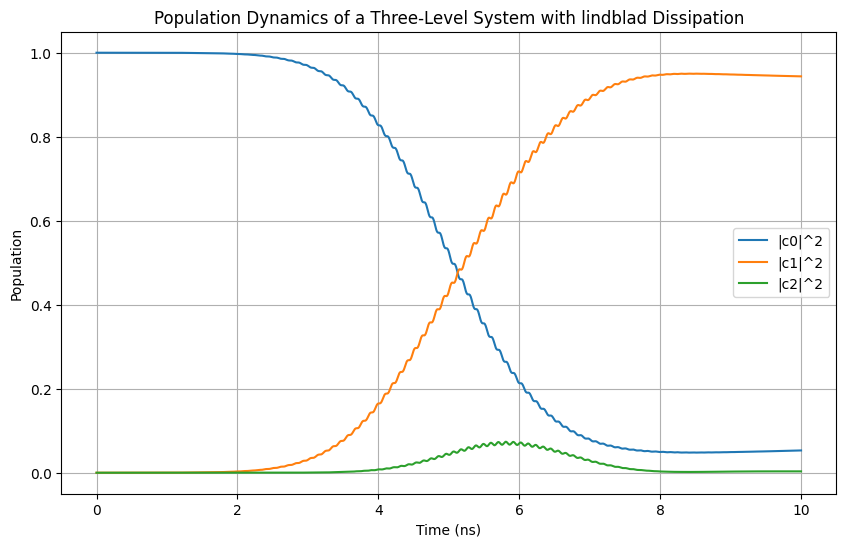

In [46]:
plt.figure(figsize=(10, 6))
plt.plot(t_L, C_L[:, 0, 0].real, label='|c0|^2')
plt.plot(t_L, C_L[:, 1, 1].real, label='|c1|^2')
plt.plot(t_L, C_L[:, 2, 2].real, label='|c2|^2')
plt.xlabel('Time (ns)')
plt.ylabel('Population')
plt.title('Population Dynamics of a Three-Level System with lindblad Dissipation')
plt.legend()
plt.grid()
plt.show()

A pi pulse is achieved at t=8.4012 ns with a maximum population of P1=0.9502


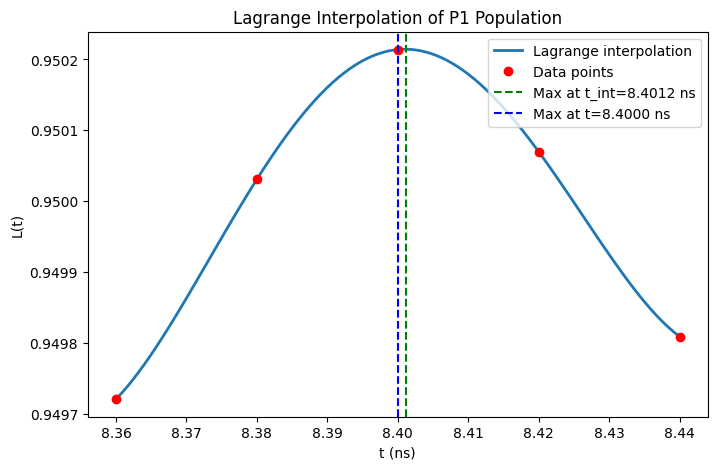

In [43]:
P1 = C_L[:, 1, 1].real
i_max = np.argmax(P1)#find the index of the maximum of P1
k=4 #number of points to use for interpolation
xp = t_L[i_max-2*k : i_max+2*k+1 : k] #interpolate around the maximum using 5 points.
yp = P1[i_max-2*k : i_max+2*k+1 : k]
x=np.linspace(xp[0], xp[-1], 100) # create an array of x values for interpolation
i_max_interp = np.argmax(lagint(x,xp,yp))
t_max_interp = x[i_max_interp]
t_max = t_L[i_max]
plt.figure(figsize=(8, 5))
plt.plot(x, lagint(x,xp,yp), lw=2, label="Lagrange interpolation")
plt.plot(xp, yp, "ro", label="Data points")
plt.axvline(t_max_interp, color='g', linestyle='--', label=f'Max at t_int={t_max_interp:.4f} ns')   
plt.axvline(t_max, color='b', linestyle='--', label=f'Max at t={t_max:.4f} ns')
plt.xlabel("t (ns)"); plt.ylabel("L(t)"); plt.title("Lagrange Interpolation of P1 Population")

plt.legend(loc='upper right') #right corner
print(f'A pi pulse is achieved at t={t_max_interp:.4f} ns with a maximum population of P1={lagint(t_max_interp,xp,yp):.4f}')
plt.show()


In [44]:
def cost_omega(omega0):
    def f(t,rho): # the function that will be used in the RK4 method to solve the Lindblad equation
        omega = omega0*gaussian(t,mu,sigma) 
        H = H_time(t,H_0,A,omega,w)
        return Lindblad(T, rho, H, gamma)
    t_L,C_L = rk4solve(f, rho0, 0, dT_g, T_g)
    P1 = C_L[:, 1, 1].real
    cost_value= 1-P1[-1] # the cost function is 1-P1 at the end of the gate time
    return cost_value


In [47]:
# then use the minimum_finder function to find the optimal omega0 that minimizes the cost function
omega_opt = minimum_finder(cost_omega, E_c/100, E_c/2, 10, 1e-4)

In [48]:
omega_opt

[np.float64(0.6966650127767513)]